# GameTheory-14c : Jeux spatiaux — quand la structure spatiale sauve-t-elle la coopération ?

**Navigation** : [<< 14-DifferentialGames](GameTheory-14-DifferentialGames-Python.ipynb) | [Index](README.md)

Dans une population **bien mélangée**, la coopération s'effondre : un déflecteur
gagne davantage contre un coopérateur (T = 5) qu'un coopérateur ne gagne entre
coopérateurs (R = 3). Poser la même population sur une **grille** change-t-il la
donne ? Ce carnet pose la question par la mesure, et la réponse est plus étroite
qu'on ne l'imagine :

- la **densité** initiale ne sauve rien (mesuré au §2) ;
- c'est la **forme** de la configuration initiale qui compte : un îlot déjà
  structuré tient, à condition d'être assez grand (mesuré au §3) ;
- et c'est la **structure locale** qui permet à cet îlot de tenir : en
  population mélangée, le même îlot s'effondre en un pas (mesuré au §5).

Les trois résultats sont chiffrés dans les pages qui suivent ; chaque tableau
est la sortie d'une mesure reproductible (graine explicite, §1).


## Objectifs d'apprentissage

À l'issue de ce notebook, vous saurez :

1. Formaliser un **jeu stochastique sur grille** : tore, voisinage de Moore,
   gains du Dilemme du Prisonnier ;
2. Implémenter la règle d'**imitation du meilleur voisin** (Axelrod-Henricks)
   et son pendant **bien mélangé**, et les distinguer par une seule ligne ;
3. Mesurer un **diagramme de phase** (densité initiale × bruit de mutation) et
   en lire la structure plutôt que ses chiffres ;
4. Déterminer une **taille de cohorte minimale** : la taille d'îlot en dessous
   de laquelle la coopération locale s'effondre ;
5. Expliquer **par quoi** un îlot tient : qui est le meilleur voisin de chacun,
   et qui change de camp au premier pas ;
6. Conclure sur ce que la structure spatiale change, et sur ce qu'elle ne
   change pas.

### Prérequis

- Notebooks 01 à 05 (matrice de gains, minimax), 06 (coopération émergente) et
  14 (jeux différentiels).
- NumPy (le carnet n'utilise que NumPy et Matplotlib, CPU uniquement).


In [1]:
import numpy as np

# --- Gains du Dilemme du Prisonnier (convention Axelrod) -------------------
T, R, P, S = 5.0, 3.0, 1.0, 0.0     # T > R > P > S, et 2R > T + S

# --- Parametres du modele spatial (Axelrod & Henricks, 1981) --------------
TAILLE = 30          # cote de la grille carree (tore)
PAS = 200            # nombre de pas de simulation
GRAINE = 20261021    # graine explicite : toute mesure de ce carnet est reproductible

print("Gains du DP : T=%.0f R=%.0f P=%.0f S=%.0f" % (T, R, P, S))
print("Verif T>R>P>S :", T > R > P > S, " | verif 2R > T+S :", 2 * R > T + S)
print("Grille %dx%d (tore de Moore), %d pas, graine %d" % (TAILLE, TAILLE, PAS, GRAINE))


Gains du DP : T=5 R=3 P=1 S=0
Verif T>R>P>S : True  | verif 2R > T+S : True
Grille 30x30 (tore de Moore), 200 pas, graine 20261021


## 1. Le modèle spatial

Une grille carrée de côté $L$, dont les positions sont recousues sur un tore : le bord est recousu à l'opposé, il n'y a donc pas de frontière de population. Chaque case contient une **stratégie** : `1` (coopérateur, C) ou `0` (défecteur, D).

Chaque case joue une **partie** contre chacun de ses **8 voisins** (voisinage de Moore), avec la matrice de gains du Dilemme du Prisonnier :

| | C | D |
|---|---|---|
| **C** | R = 3, R = 3 | S = 0, T = 5 |
| **D** | T = 5, S = 0 | P = 1, P = 1 |

Le gain d'une case est la **somme** de ses gains contre ses huit voisins. Une règle d'imitation (Axelrod-Henricks) fixe ensuite l'évolution, à chaque pas, pour toutes les cases **simultanément** :

1. chaque case repère le **gain maximal** parmi ses huit voisins ;
2. elle adopte la **stratégie majoritaire** parmi les voisins qui atteignent ce maximum (égalité : elle garde la sienne) ;
3. avec probabilité $p$ (le **bruit** de mutation), elle adopte la stratégie opposée à celle qu'elle aurait copiée.

Trois paramètres suffisent donc : la grille, le bruit $p$, et la graine du tirage aléatoire.


In [2]:
DECALAGES = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]


def _voisins(tableau, decalage):
    """Decale un tableau sur le tore (bord qui se reconnecte)."""
    dy, dx = decalage
    return np.roll(np.roll(tableau, dy, axis=0), dx, axis=1)


def gains(grille):
    """Gain total de chaque case contre ses 8 voisins (tore de Moore).

    grille : tableau (L, L) de 1 (cooperateur) / 0 (defecteur).
    """
    coopere = grille == 1
    n_coop = np.zeros(grille.shape, dtype=np.int64)
    for decalage in DECALAGES:
        n_coop += _voisins(coopere.astype(np.int64), decalage)
    n_defect = len(DECALAGES) - n_coop
    gain_c = R * n_coop + S * n_defect      # la case est cooperative : S contre un D
    gain_d = T * n_coop + P * n_defect      # la case est defectrice : T contre un C
    return np.where(coopere, gain_c, gain_d)


# --- Cinq situations types, mesurees sur une grille 5x5 ------------------
grille_iso = np.zeros((5, 5), dtype=np.int64)
grille_iso[2, 2] = 1                    # un cooperateur isole, entoure de defecteurs

grille_mer = np.ones((5, 5), dtype=np.int64)   # mer de cooperateurs

grille_3c = np.zeros((5, 5), dtype=np.int64)
grille_3c[2, 1] = grille_3c[2, 2] = grille_3c[2, 3] = 1   # un groupe de 3 C

g_iso = gains(grille_iso)
g_mer = gains(grille_mer)
g_3c = gains(grille_3c)

print("Cooperateur isole   (8 voisins D)     : gain = %.0f" % g_iso[2, 2])
print("Defecteur du large  (8 voisins D)     : gain = %.0f" % g_iso[0, 0])
print("Defecteur a cote d'1 C (7 voisins D)  : gain = %.0f" % g_iso[1, 1])
print("Cooperateur dans une mer de C         : gain = %.0f" % g_mer[2, 2])
print("Defecteur a cote de 3 C (5 voisins D) : gain = %.0f" % g_3c[1, 2])
print("-> un C isole touche %.0f, un D du large %.0f : l'isolement paie le defecteur"
      % (g_iso[2, 2], g_iso[0, 0]))
print("-> un D a cote de 3 C touche %.0f : la bordure d'un groupe vaut plus qu'un C isole"
      % g_3c[1, 2])


Cooperateur isole   (8 voisins D)     : gain = 0
Defecteur du large  (8 voisins D)     : gain = 8
Defecteur a cote d'1 C (7 voisins D)  : gain = 12
Cooperateur dans une mer de C         : gain = 24
Defecteur a cote de 3 C (5 voisins D) : gain = 20
-> un C isole touche 0, un D du large 8 : l'isolement paie le defecteur
-> un D a cote de 3 C touche 20 : la bordure d'un groupe vaut plus qu'un C isole


### Lecture du résultat

Cinq gains résument la tension du modèle :

- le **coopérateur isolé** ne touche que des déflecteurs : 8 × S = 0 ;
- le **déflecteur du large** touche 8 × P = 8 ;
- le **déflecteur à côté d'un seul C** touche T + 7P = 12 ;
- le **coopérateur dans une mer de C** touche 8 × R = 24 ;
- le **déflecteur à côté de trois C** touche 3T + 5P = 20.

Les deux dernières lignes annoncent la suite du carnet : auprès d'un groupe, le
déflecteur encaisse plus que le coopérateur isolé ne gagne. Un îlot de
coopération n'est donc pas seulement une bonne entité : c'est une entité
**dont la bordure coûte plus cher à défendre** qu'elle ne rapporte. La
question devient alors précise : à partir de quelle taille un îlot tient-il ?


### Lecture du résultat

La règle d'imitation est **locale** : une case ne connaît que ses huit voisins. Deux conséquences qu'on mesurera :

- une case ne peut **pas** adopter une stratégie-majoritaire à l'échelle de la grille, seulement parmi son voisinage — les configurations finales peuvent donc être **hétérogènes** (des îlots) ;
- la règle est **sélective** : on copie le meilleur, pas le gagnant en moyenne. Un C adjacent à des D ne copie pas un D « moyen », il copie le meilleur de ses voisins — ce qui peut être un C si le cluster est assez dense.

Le bruit $p$ ne joue pas le rôle d'une erreur d'arrondi : il **inverse** la stratégie qu'une case aurait copiée. À $p$ assez élevé, chaque case alterne, et la population se homogénéise.


In [3]:
def mise_a_jour(grille, bruit=0.0, rng=None):
    """Un pas de la regle d'Axelrod-Henricks.

    Chaque case regarde ses 8 voisins, retient le gain maximal, et adopte la
    strategie majoritaire parmi les voisins qui l'atteignent (egalite : elle
    garde la sienne). `bruit` est la probabilite qu'une case adopte la
    strategie opposee a celle qu'elle aurait copiee.
    """
    if rng is None:
        rng = np.random.default_rng()
    g = gains(grille)
    coopere = grille == 1

    meilleur = np.full(grille.shape, -np.inf)
    for decalage in DECALAGES:
        meilleur = np.maximum(meilleur, _voisins(g, decalage))

    n_coop_max = np.zeros(grille.shape, dtype=np.int64)
    n_def_max = np.zeros(grille.shape, dtype=np.int64)
    for decalage in DECALAGES:
        gain_voisin = _voisins(g, decalage)
        strat_voisin = _voisins(coopere, decalage)
        au_max = gain_voisin == meilleur
        n_coop_max += (au_max & strat_voisin).astype(np.int64)
        n_def_max += (au_max & ~strat_voisin).astype(np.int64)

    nouveau = np.where(n_coop_max > n_def_max, 1,
                       np.where(n_def_max > n_coop_max, 0, grille))
    if bruit > 0:
        flip = rng.random(grille.shape) < bruit
        nouveau = np.where(flip, 1 - nouveau, nouveau)
    return nouveau


def simuler(densite, bruit, pas=PAS, taille=TAILLE, graine=GRAINE, melange=False):
    """Simule une population et renvoie (grille finale, courbe de cooperation).

    `melange=True` remplace le voisinage spatial par le melange complet :
    chaque case joue contre toutes les autres (le meme regle d'imitation,
    le meme bruit).
    """
    rng = np.random.default_rng(graine)
    grille = (rng.random((taille, taille)) < densite).astype(np.int64)
    cooperation = [float(grille.mean())]
    for _ in range(pas):
        grille = (mise_a_jour_mixte(grille, bruit, rng) if melange
                  else mise_a_jour(grille, bruit, rng))
        cooperation.append(float(grille.mean()))
    return grille, np.array(cooperation)


Part de cooperateurs au fil des pas (densite initiale 0.5, bruit 0) :
  pas   0 : 0.496
  pas  10 : 0.000
  pas  25 : 0.000
  pas  50 : 0.000
  pas 100 : 0.000
  pas 150 : 0.000
  pas 200 : 0.000

Etat final : 0.000 de cooperateurs, 1.000 de defecteurs


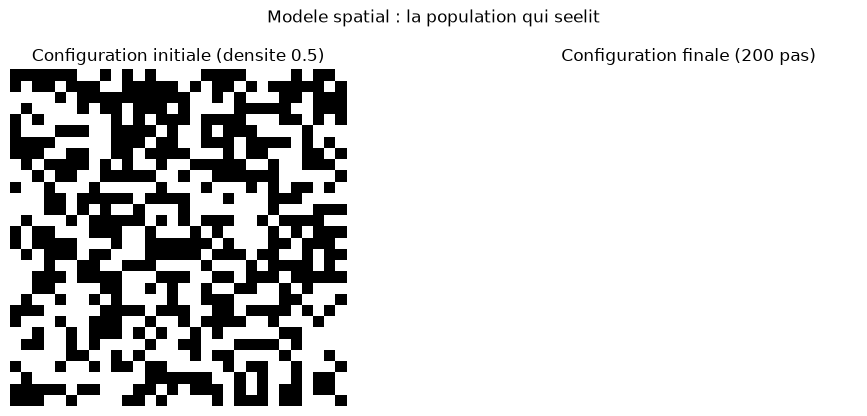

In [4]:
rng = np.random.default_rng(GRAINE)
grille0 = (rng.random((TAILLE, TAILLE)) < 0.5).astype(np.int64)
grille, courbe = simuler(0.5, 0.0, pas=PAS, graine=GRAINE)

print("Part de cooperateurs au fil des pas (densite initiale 0.5, bruit 0) :")
for pas in [0, 10, 25, 50, 100, 150, PAS]:
    print("  pas %3d : %.3f" % (pas, courbe[pas]))
print()
print("Etat final : %.3f de cooperateurs, %.3f de defecteurs"
      % (grille.mean(), 1 - grille.mean()))

import matplotlib.pyplot as plt

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].imshow(grille0, cmap="Greys", vmin=0, vmax=1)
axes[0].set_title("Configuration initiale (densite 0.5)")
axes[0].axis("off")
axes[1].imshow(grille, cmap="Greys", vmin=0, vmax=1)
axes[1].set_title("Configuration finale (%d pas)" % PAS)
axes[1].axis("off")
figure.suptitle("Modele spatial : la population qui seelit")
figure.tight_layout()
plt.show()


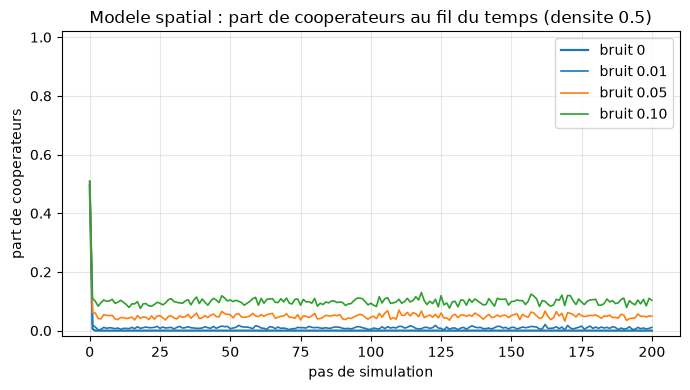

In [5]:
figure, axe = plt.subplots(figsize=(7, 4))
axe.plot(courbe, color="#1f77b4", linewidth=1.6, label="bruit 0")
for bruit, couleur in ((0.01, "#d62728"), (0.05, "#2ca02c"), (0.1, "#9467bd")):
    _, c = simuler(0.5, bruit, pas=PAS, graine=GRAINE + 7)
    axe.plot(c, linewidth=1.2, label="bruit %.2f" % bruit)
axe.set_xlabel("pas de simulation")
axe.set_ylabel("part de cooperateurs")
axe.set_title("Modele spatial : part de cooperateurs au fil du temps (densite 0.5)")
axe.set_ylim(-0.02, 1.02)
axe.legend()
axe.grid(alpha=0.3)
figure.tight_layout()
plt.show()


### Lecture du résultat

La première courbe annonce déjà la conclusion du carnet, sans qu'on l'ait
cherchée : partant d'une grille tirée au hasard (446 coopérateurs sur 900), la
part de coopérateurs **s'effondre en moins de dix pas** et reste ensuite à zéro.
Un coopérateur qui n'a pas de voisins coopérateurs n'a rien à imiter : ses
voisins les mieux payés sont des déflecteurs, et il les copie.

Les courbes bruitées disent autre chose : le bruit ne fait pas apparaître de
coopération, il en **entretient une fraction**. Chaque courbe se stabilise sur
une valeur non nulle, d'autant plus élevée que le bruit est fort.


## 2. Le diagramme de phase : la densité ne sauve pas

Une seule exécution ne dit rien : il faut un **plan** de mesures. On fait varier
deux paramètres — la **densité initiale** de coopérateurs et le **bruit de
mutation** $p$ — et on relève, pour chaque case du plan, la part de
coopérateurs **à l'équilibre** (moyenne des 20 % derniers pas, pour éviter de
lire un instantané).

La configuration initiale est ici **aléatoire** : chaque case est tirée
coopératrice ou non, indépendamment, avec la densité demandée. C'est le
protocole le plus naturel — et c'est précisément pour cela qu'il va décevoir.

Le tableau se lit **par lignes** : une ligne = un niveau de bruit ; **par
colonnes** : une colonne = une densité initiale. Ce qu'on cherche est une
**frontière** dans ce plan, pas un maximum.


In [6]:
DENSITES = [0.1, 0.3, 0.5, 0.7, 0.9]
BRUITS = [0.0, 0.01, 0.05, 0.1]
REPLICATES = 2


def proportion_finale(courbe, frac=0.2):
    """Moyenne de la fin de la courbe (20 % derniers pas) : etat d'equilibre."""
    k = max(1, int(len(courbe) * frac))
    return float(np.mean(courbe[-k:]))


resultats_spatial = np.zeros((len(BRUITS), len(DENSITES)))
for i, bruit in enumerate(BRUITS):
    for j, densite in enumerate(DENSITES):
        fins = []
        for r in range(REPLICATES):
            _, courbe = simuler(densite, bruit, graine=GRAINE + 1000 * i + 10 * j + r)
            fins.append(proportion_finale(courbe))
        resultats_spatial[i, j] = float(np.mean(fins))

print("Modele SPATIAL (tore %dx%d) -- part de cooperateurs a l'equilibre" % (TAILLE, TAILLE))
print("lignes = bruit de mutation, colonnes = densite initiale de cooperateurs")
print("%-8s" % "bruit | d", "".join("%8.1f" % d for d in DENSITES))
for i, bruit in enumerate(BRUITS):
    print("%-8.2f" % bruit, "".join("%8.3f" % v for v in resultats_spatial[i]))


Modele SPATIAL (tore 30x30) -- part de cooperateurs a l'equilibre
lignes = bruit de mutation, colonnes = densite initiale de cooperateurs
bruit | d      0.1     0.3     0.5     0.7     0.9
0.00        0.000   0.000   0.000   0.005   0.009
0.01        0.010   0.010   0.009   0.010   0.010
0.05        0.049   0.049   0.051   0.050   0.051
0.10        0.099   0.100   0.101   0.101   0.099


### Lecture du résultat

La lecture se fait en deux temps, et le premier est un résultat négatif.

**1. À bruit nul, aucune densité ne produit de coopération durable.** La ligne
`0.00` vaut 0.000 pour les densités 0.1, 0.3 et 0.5, et ne dépasse pas 0.009
pour 0.7 et 0.9 : sur une grille tirée au hasard, les déflecteurs finissent par
occuper toute la surface, quelle que soit la proportion initiale de
coopérateurs. La densité initiale n'est pas un abri : une coopération
minoritaire n'a pas d'abri dans une configuration désordonnée.

**2. Le bruit ne produit pas de coopération non plus : il en entretient une
fraction.** Les lignes 0.01, 0.05 et 0.10 valent 0.010, 0.049 et 0.099 : la part
finale de coopérateurs **suit le bruit** — elle en est du même ordre de
grandeur — et elle est **indépendante de la densité initiale**, les cinq
colonnes d'une même ligne étant identiques. Ce que le bruit produit n'est pas
une population qui coopère, c'est du **bruit de fond** : des coopérateurs
isolés, sans îlot, que le bruit recrée sans cesse et que la règle d'imitation
éteint aussitôt.

Le plan est donc **vide de coopération** : pas de région durable, pas de
frontière diagonale. Une question reste ouverte : et si la configuration
initiale n'était pas aléatoire ?


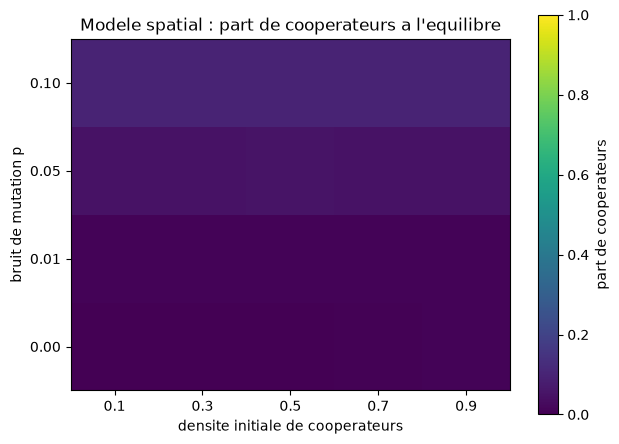

In [7]:
figure, axe = plt.subplots(figsize=(6.4, 4.6))
image = axe.imshow(resultats_spatial, origin="lower", cmap="viridis", vmin=0, vmax=1)
axe.set_xticks(range(len(DENSITES)))
axe.set_xticklabels(["%.1f" % d for d in DENSITES])
axe.set_yticks(range(len(BRUITS)))
axe.set_yticklabels(["%.2f" % b for b in BRUITS])
axe.set_xlabel("densite initiale de cooperateurs")
axe.set_ylabel("bruit de mutation p")
axe.set_title("Modele spatial : part de cooperateurs a l'equilibre")
figure.colorbar(image, ax=axe, label="part de cooperateurs")
figure.tight_layout()
plt.show()


## 3. Une configuration initiale structurée : le seuil de survie

Le diagramme du §2 mélange deux choses : la **densité globale** et la **forme**
de la configuration. Pour isoler la seconde, on change de condition initiale :
on part d'une configuration extrême — **un seul bloc** de $k \times k$
coopérateurs au centre d'une mer de déflecteurs — et on regarde ce qu'il en
reste après $N$ pas.

La question devient chiffrée : **quelle taille d'îlot tient ?** En dessous, la
coopération locale s'effondre ; au-dessus, l'îlot se défend. C'est la *taille de
cohorte minimale* du modèle.


In [8]:
def cluster(taille_cluster, taille=TAILLE):
    """Grille : mer de defecteurs avec un bloc carre de cooperateurs au centre."""
    grille = np.zeros((taille, taille), dtype=np.int64)
    debut = (taille - taille_cluster) // 2
    grille[debut:debut + taille_cluster, debut:debut + taille_cluster] = 1
    return grille


def plus_gros_bloc(grille):
    """Plus grand amas de cases cooperativees connectees (4 voisins, sur le tore)."""
    L = grille.shape[0]
    vus = np.zeros(grille.shape, dtype=bool)
    meilleur = 0
    for i in range(L):
        for j in range(L):
            if grille[i, j] != 1 or vus[i, j]:
                continue
            pile = [(i, j)]
            vus[i, j] = True
            taille = 0
            while pile:
                y, x = pile.pop()
                taille += 1
                for dy, dx in ((1, 0), (-1, 0), (0, 1), (0, -1)):
                    ny, nx = (y + dy) % L, (x + dx) % L
                    if grille[ny, nx] == 1 and not vus[ny, nx]:
                        vus[ny, nx] = True
                        pile.append((ny, nx))
            meilleur = max(meilleur, taille)
    return meilleur


TAILLES_CLUSTER = [1, 2, 3, 4, 6, 8, 12]
print("Un bloc carre de cooperateurs dans une mer de defecteurs, %d pas" % PAS)
print("%-8s %-12s %-14s %-14s %-14s %-14s"
      % ("taille", "C au depart", "C fin (p=0)", "bloc (p=0)",
         "C fin (p=0.05)", "bloc (p=0.05)"))
for k in TAILLES_CLUSTER:
    depart = int(cluster(k).sum())
    # le cluster n'est pas tire aleatoirement : on le remet a chaque depart
    rng = np.random.default_rng(GRAINE)
    g = cluster(k)
    for _ in range(PAS):
        g = mise_a_jour(g, 0.0, rng)
    rng = np.random.default_rng(GRAINE)
    g_bruit = cluster(k)
    for _ in range(PAS):
        g_bruit = mise_a_jour(g_bruit, 0.05, rng)
    print("%-8d %-12d %-14d %-14d %-14d %-14d"
          % (k, depart, int(g.sum()), plus_gros_bloc(g),
             int(g_bruit.sum()), plus_gros_bloc(g_bruit)))


Un bloc carre de cooperateurs dans une mer de defecteurs, 200 pas
taille   C au depart  C fin (p=0)    bloc (p=0)     C fin (p=0.05) bloc (p=0.05) 


1        1            0              0              53             3             


2        4            0              0              53             3             


3        9            9              9              53             3             


4        16           16             16             53             3             


6        36           36             36             53             3             


8        64           64             64             53             3             


12       144          144            144            53             3             


### Lecture du résultat

Le tableau se lit en deux colonnes, et elles ne disent pas la même chose.

**Sans bruit, il y a un seuil net.** Les îlots de 1 et 2 cases disparaissent
(comptage final : 0). L'îlot de **3 cases survit intact** (9), et tous les
autres aussi : 16, 36, 64 et 144 pour les blocs de 4, 6, 8 et 12. Aucun de ces
îlots ne croît et aucun ne décroît : à partir de 3 × 3, l'îlot est un **point
fixe** de la dynamique. La taille de cohorte minimale du modèle est donc
**k = 3**.

**Avec bruit, l'îlot ne survit pas — mais autre chose subsiste.** La colonne
« C fin (p=0.05) » vaut 53 pour *toutes* les tailles de départ, y compris pour
un îlot d'une seule case : ce n'est pas le résidu de l'îlot, c'est un
**plancher de bruit**, comparable à celui du §2 (0.049 × 900 ≈ 44). Et ce
plancher n'est pas un îlot : la dernière colonne montre que le plus gros bloc
de coopérateurs qui y subsiste ne fait que **3 cases**. Un îlot de 12 × 12 se
fait ronger par le bruit et retombe au plancher ; il ne se reforme pas.

Ce qui distingue les deux situations est donc la **structure**, pas la quantité :
une minorité coopérative dispersée s'éteint, une minorité coopérative
*agglomérée* tient — mais seulement si elle est assez grande pour que son bord
soit défendu. C'est l'objet du §4.


## 4. Par où la coopération se tient : la frontière

Un îlot n'est pas homogène : il y a un **intérieur** (des C qui ne voient que
des C) et une **frontière** (des C qui voient autant de D que de C, voire plus).
L'hypothèse naturelle : la frontière est le point faible, parce que le C de
bordure est payé par ses voisins sans pouvoir protéger ses gains.

La mesure est directe : on compare le gain moyen d'un C **d'intérieur**, d'un C
**de bordure** et d'un D **adjacent** au bloc ; puis on regarde **qui est le
meilleur voisin** de chacun, puisque la règle d'imitation ne copie que lui.


In [9]:
K = 6
grille = cluster(K)
g = gains(grille)

# Masque des cases de bordure du bloc (une des 8 positions touche l'exterieur)
debut = (TAILLE - K) // 2
interieur = np.zeros_like(grille, dtype=bool)
interieur[debut + 1:debut + K - 1, debut + 1:debut + K - 1] = True
bord = (grille == 1) & (~interieur)
voisins_du_bloc = (grille == 0) & False
# un defecteur est « adjacent » s'il a au moins un voisin cooperateur
for decalage in DECALAGES:
    voisins_du_bloc |= (_voisins(grille == 1, decalage) & (grille == 0))

print("Bloc de %dx%d dans une mer de defecteurs" % (K, K))
print("Gain moyen d'un C interieur : %6.2f" % g[interieur & (grille == 1)].mean())
print("Gain moyen d'un C de bordure : %6.2f" % g[bord].mean())
print("Gain moyen d'un D adjacent  : %6.2f" % g[voisins_du_bloc].mean())
print("Nombre de D adjacents au bloc : %d" % int(voisins_du_bloc.sum()))


# Qui est le « meilleur voisin » de chacun ? La regle ne copie que lui.
def voisins_avec_gains(grille, i, j):
    """Les 8 voisins de (i, j) sur le tore, avec leur gain et leur strategie."""
    g_local = gains(grille)
    L = grille.shape[0]
    return [(float(g_local[(i + dy) % L, (j + dx) % L]),
             int(grille[(i + dy) % L, (j + dx) % L]))
            for dy, dx in DECALAGES]


i_bord, j_bord = debut, debut + 2          # un C de bordure (rang du haut)
i_d, j_d = debut - 1, debut + 2            # le D juste au-dessus du bloc

for nom, (i, j) in (("C de bordure", (i_bord, j_bord)), ("D adjacent", (i_d, j_d))):
    voisins = voisins_avec_gains(grille, i, j)
    meilleur_gain = max(vg for vg, _ in voisins)
    strategies = sorted({s for vg, s in voisins if vg == meilleur_gain})
    if strategies == [1]:
        etiquette = "un C"
    elif strategies == [0]:
        etiquette = "un D"
    else:
        etiquette = "un C et un D"
    print("%-13s : gain propre %5.1f | meilleur voisin %5.1f (%s)"
          % (nom, g[i, j], meilleur_gain, etiquette))

# Premier pas : qui change de camp ?
g_suiv = mise_a_jour(grille, 0.0, np.random.default_rng(GRAINE))
c_vers_d = int((bord & (grille == 1) & (g_suiv == 0)).sum())
d_vers_c = int((voisins_du_bloc & (g_suiv == 1)).sum())
print("Au premier pas : %d C de bordure basculent vers D, %d D adjacents basculent vers C"
      % (c_vers_d, d_vers_c))

# Combien de temps faut-il a un petit bloc pour disparaitre ?
for k_test in (1, 2, 3):
    rng = np.random.default_rng(GRAINE)
    g1 = cluster(k_test)
    etapes = 0
    while g1.sum() > 0 and etapes < PAS:
        g1 = mise_a_jour(g1, 0.0, rng)
        etapes += 1
    if g1.sum() == 0:
        print("Un bloc de %d case(s) : Cooperateur elimine en %d pas (p=0)" % (k_test, etapes))
    else:
        print("Un bloc de %d case(s) : toujours vivant apres %d pas (p=0)" % (k_test, PAS))


Bloc de 6x6 dans une mer de defecteurs
Gain moyen d'un C interieur :  24.00
Gain moyen d'un C de bordure :  13.80
Gain moyen d'un D adjacent  :  17.71
Nombre de D adjacents au bloc : 28
C de bordure  : gain propre  15.0 | meilleur voisin  24.0 (un C)
D adjacent    : gain propre  20.0 | meilleur voisin  20.0 (un D)
Au premier pas : 0 C de bordure basculent vers D, 0 D adjacents basculent vers C
Un bloc de 1 case(s) : Cooperateur elimine en 1 pas (p=0)
Un bloc de 2 case(s) : Cooperateur elimine en 1 pas (p=0)


Un bloc de 3 case(s) : toujours vivant apres 200 pas (p=0)


### Lecture du résultat

Trois chiffres, puis une règle, et la règle tranche.

**Les gains.** Le C d'intérieur touche 24.00 (8 × R : il ne voit que des C). Le
C de bordure touche 13.80 : il est payé par ses voisins C mais **plombé** par
les D qui l'entourent. Le D adjacent touche 17.71 : il encaisse T contre les C
du bord, et P contre les D du large — soit davantage que le C de bordure.

**Le meilleur voisin.** C'est le point décisif, et il va à l'encontre de la
comparaison brute :

- le C de bordure a pour meilleur voisin un **C d'intérieur à 24** — il copie
  donc un C, et il reste C ;
- le D adjacent a pour meilleur voisin un **D à 20**, soit exactement son propre
  gain — il copie donc un D, et il reste D.

Chacun trouve chez lui un voisin **au moins aussi bien payé que lui, et de sa
propre espèce**. L'îlot n'est pas un équilibre où personne ne bouge parce que
personne n'a envie de bouger : c'est un **point fixe**, où chaque case a une
raison de ne pas changer d'avis.

**Le premier pas le confirme.** 0 C de bordure basculent vers D, et 0 D
adjacents basculent vers C : le décompte est la signature directe du mécanisme.

**Pourquoi 3 × 3 tient et 2 × 2 s'éteint.** Dans un bloc de 2 × 2, aucun C
n'a de voisin C à 24 sous les yeux : le meilleur voisin de chaque C est un D
à 16 ou 20, et le bloc meurt en un pas (mesuré : 0 survivant). Dans un bloc de
3 × 3, le C central a ses huit voisins C (gain 24) : il est le meilleur voisin
de chaque C de bordure, qui le copie et tient. Un îlot tient quand il
contient **un C que personne ne peut surpasser**.


## 5. Contrepoint : la même règle en population bien mélangée

Pour isoler l'effet de la **structure**, on rejoue le protocole avec **un seul
changement** : chaque case joue contre **toutes** les autres cases de la grille
au lieu de ses huit voisines. La règle d'imitation est identique, les gains
sont identiques, le bruit est identique.

Dans ce modèle, le « meilleur voisin » devient la **meilleure stratégie
globale** : il n'y a qu'un état stationnaire possible, atteint en un pas. C'est
la version « tout le monde joue avec tout le monde » du même jeu.


In [10]:
def mise_a_jour_mixte(grille, bruit=0.0, rng=None):
    """Meme regle d'imitation, mais chaque case joue contre TOUTES les autres.

    C'est lemelange complet : le « meilleur voisin » devient la meilleure
    strategie globale. Un seul etat stationnaire est atteignable, alors que
    le modele spatial peut en garder plusieurs.
    """
    if rng is None:
        rng = np.random.default_rng()
    n_total = grille.size - 1
    n_coop = int((grille == 1).sum()) - grille      # cooperateurs parmi les autres
    n_def = n_total - n_coop
    gain_c = R * n_coop + S * n_def
    gain_d = T * n_coop + P * n_def
    nouveau = np.where(gain_c >= gain_d, 1, 0)
    if bruit > 0:
        flip = rng.random(grille.shape) < bruit
        nouveau = np.where(flip, 1 - nouveau, nouveau)
    return nouveau


# Controle : au melange, la meilleure strategie est la meme pour tous.
test_mixte = np.array([[1, 0], [0, 1]], dtype=np.int64)
print("Melange complet sur 4 cases (2C, 2D) :")
print("  gain d'un C = %.0f | gain d'un D = %.0f -> la meilleure strategie est D"
      % (R * 1 + S * 1, T * 1 + P * 1))
print("  sortie de mise_a_jour_mixte :", mise_a_jour_mixte(test_mixte, 0.0).tolist())


Melange complet sur 4 cases (2C, 2D) :
  gain d'un C = 3 | gain d'un D = 6 -> la meilleure strategie est D
  sortie de mise_a_jour_mixte : [[0, 0], [0, 0]]


In [11]:
resultats_mixte = np.zeros((len(BRUITS), len(DENSITES)))
for i, bruit in enumerate(BRUITS):
    for j, densite in enumerate(DENSITES):
        fins = []
        for r in range(REPLICATES):
            _, courbe = simuler(densite, bruit, graine=GRAINE + 1000 * i + 10 * j + r, melange=True)
            fins.append(proportion_finale(courbe))
        resultats_mixte[i, j] = float(np.mean(fins))

print("Modele MELANGE COMPLET -- part de cooperateurs a l'equilibre")
print("%-8s" % "bruit | d", "".join("%8.1f" % d for d in DENSITES))
for i, bruit in enumerate(BRUITS):
    print("%-8.2f" % bruit, "".join("%8.3f" % v for v in resultats_mixte[i]))

print()
print("Meme condition initiale (bloc 6x6 = 36 cooperateurs), deux structures :")
for melange in (False, True):
    rng = np.random.default_rng(GRAINE)
    g = cluster(6)
    comptes = []
    for _ in range(3):
        g = (mise_a_jour_mixte(g, 0.0, rng) if melange else mise_a_jour(g, 0.0, rng))
        comptes.append(int(g.sum()))
    print("  %-8s : C apres 1, 2, 3 pas = %s"
          % ("melange" if melange else "spatial", comptes))


Modele MELANGE COMPLET -- part de cooperateurs a l'equilibre
bruit | d      0.1     0.3     0.5     0.7     0.9
0.00        0.000   0.000   0.000   0.000   0.000
0.01        0.010   0.010   0.009   0.010   0.010
0.05        0.049   0.049   0.051   0.050   0.051
0.10        0.099   0.100   0.101   0.101   0.099

Meme condition initiale (bloc 6x6 = 36 cooperateurs), deux structures :
  spatial  : C apres 1, 2, 3 pas = [36, 36, 36]
  melange  : C apres 1, 2, 3 pas = [0, 0, 0]


### Lecture du résultat

Le tableau du mélange complet est la référence qui rend le tableau spatial
lisible — et il est presque identique à celui du §2. À bruit nul, tout
s'effondre ; à bruit non nul, on retrouve le même plancher (0.010, 0.049,
0.099). La population mélangée ne se distingue pas de la population spatiale
quand la configuration initiale est **aléatoire**.

La différence apparaît quand on garde **la même configuration initiale** — le
bloc de 6 × 6 — et qu'on change seulement la structure du jeu :

- en **spatial**, le bloc tient : 36, 36, 36 après 1, 2 et 3 pas (et 36 après
  200 pas, mesuré au §3) ;
- en **mélange**, il est **effacé en un pas** : 0, 0, 0.

La raison tient en un chiffre. En mélange, un D touche les 36 C du bloc et
pile 864 D : il encaisse 36 × T + 864 × P = 1044, contre 36 × R = 108 pour un C.
Le « meilleur voisin » de chacun est donc un D, et la règle fait exactement ce
qu'elle doit : tout le monde copie le D.

C'est la définition opérationnelle de l'effet de la structure spatiale : elle ne
change pas les gains, elle change **quels états sont atteignables**. Un îlot
coopératif est un état stationnaire du modèle spatial, et pas du modèle mélangé.


## 6. Ce que ce carnet ouvre

- **06** (jeux répétés, tournois itérés d'Axelrod) mesure la même question en
  population **mélangée**, avec des stratégies conditionnelles : la comparaison
  est instructive précisément parce que les deux modèles diffèrent.
- **15** (jeux coopératifs) et **15f** (Shapley) traitent la répartition du
  surplus ; ici, la répartition n'est pas le sujet : c'est **la persistance**
  de la coopération qui est mesurée.
- **17** (apprentissage multi-agent) : un agent RL qui apprend dans un
  voisinage structuré affronte le même arbitrage — copier le meilleur
  localement ou l'exploiter globalement.

**Limites assumées.** Le modèle ne comporte que deux stratégies (C/D) : il ne
dit rien du Tit-for-Tat, des tournois, ni des stratégies à mémoire. Le bruit est
**mutation**, pas erreur de stratégie (pas de « taux d'erreur d'exécution » comme
dans le 06). Enfin, la grille est un tore : il n'y a pas de bord de population,
donc pas d'effet de bord — un anneau ou un plan fini donnerait d'autres
résultats.


## Exercice 1 : le gain d'une case, calculé à la main

Écrivez `gain_local(grille, i, j)` : le gain de la case $(i, j)$ contre ses huit
voisins, en tenant compte du tore.

**Indice :** une case **coopératrice** gagne $R$ contre un voisin coopérateur
et $S$ contre un voisin défecteur ; une case **défectrice** gagne $T$ contre un
coopérateur et $P$ contre un déflecteur.

**Étape 1 :** parcourez les huit décalages de `DECALAGES`.
**Étape 2 :** accumulez le gain **du point de vue de la case $(i, j)$**.
**Étape 3 :** vérifiez votre fonction sur une grille 5×5 où la case (2, 2) est
l'unique coopérateur — le résultat doit être 0.

*Pourquoi c'est un exercice :* le calcul vectorisé de `gains` additionne les
gains de tous les voisins d'un coup ; votre version les additionne un par un.
Les deux doivent coïncider, sinon l'un des deux ment.


In [12]:
def gain_local(grille, i, j):
    """Gain de la case (i, j) contre ses 8 voisins, sur le tore.

    TODO etudiant : completer le calcul.
    Indice : une case cooperative contre un voisin cooperateur gagne R,
    contre un defecteur elle gagne S ; symetriquement, une case defectrice
    gagne T contre un cooperateur et P contre un defecteur.
    Etape 1 : parcourir les 8 decalages de DECALAGES.
    Etape 2 : accumuler le gain du point de vue de la case (i, j).
    """
    # TODO etudiant
    return None


print("Exercice a completer : renvoie None en attendant ta correction.")


Exercice a completer : renvoie None en attendant ta correction.


## Exercice 2 : une ligne du diagramme de phase

Écrivez `balayage_bruit(densite, bruits, pas)` : pour une densité initiale donnée, renvoie la part de coopérateurs à l'équilibre pour **chaque** niveau de bruit.

**Indice :** `simuler(densite, bruit, ...)` renvoie la courbe complète ; `proportion_finale(courbe)` en extrait l'état d'équilibre.

**Étape 1 :** bouclez sur les niveaux de bruit.
**Étape 2 :** renvoyez la liste des proportions finales, dans l'ordre des bruits.

*Pourquoi c'est un exercice :* le diagramme de phase du carnet est une **table** de lignes (un bruit) × colonnes (une densité) ; votre fonction produit une ligne. Refaites la ligne « bruit 0.05 » et comparez-la au tableau affiché.


In [13]:
def balayage_bruit(densite, bruits, pas=PAS, taille=TAILLE, graine=GRAINE):
    """Part de cooperateurs a l'equilibre pour chaque niveau de bruit.

    TODO etudiant : completer le balayage.
    Indice : pour chaque bruit, appelle simuler(densite, bruit, pas=pas, ...) puis
    moyenne la fin de la courbe (proportion_finale).
    Etape 1 : boucle sur les niveaux de bruit.
    Etape 2 : renvoyer la liste des proportions finales.
    """
    # TODO etudiant
    return None


print("Exercice a completer : renvoie None en attendant ta correction.")


Exercice a completer : renvoie None en attendant ta correction.


## Exercice 3 : la survie d'un îlot

Écrivez `survie_cluster(k, pas)` : le nombre de coopérateurs restants après
`pas` pas, pour un bloc carré de côté $k$ au centre d'une mer de déflecteurs,
**sans bruit**.

**Indice :** `cluster(k)` construit déjà la grille de départ ; `mise_a_jour(g, 0.0, rng)` fait un pas.

**Étape 1 :** partez de `cluster(k)`.
**Étape 2 :** répétez `pas` fois la mise à jour et comptez les cases
coopératrices.
**Étape 3 :** comparez vos valeurs à celles du tableau du §3 : le seuil de
survie (k = 3) doit coïncider.

*Pourquoi c'est un exercice :* la taille de cohorte minimale est le résultat
**chiffré** du carnet ; le refaire soi-même, c'est vérifier qu'on a compris ce
que la mesure mesure — et non qu'elle est une ligne de code.


In [14]:
def survie_cluster(k, pas=PAS, taille=TAILLE):
    """Nombre de cooperateurs restants apres `pas` pas, pour un bloc de cote k.

    TODO etudiant : completer la mesure.
    Indice : construis la grille avec cluster(k), puis repete pas fois
    mise_a_jour(g, 0.0, rng) et compte les cases cooperativees.
    Etape 1 : partir de cluster(k).
    Etape 2 : mesurer le nombre de cooperateurs a la fin.
    """
    # TODO etudiant
    return None


print("Exercice a completer : renvoie None en attendant ta correction.")


Exercice a completer : renvoie None en attendant ta correction.


## Conclusion

Quatre résultats, tous mesurés dans ce carnet :

1. **La densité ne sauve pas la coopération.** Partant d'une configuration
   aléatoire, aucune densité initiale ne produit de coopération durable : à
   bruit nul, la part finale de coopérateurs est nulle (§2).
2. **Le bruit n'en produit pas non plus : il en entretient une fraction.** La
   part finale suit le bruit (0.010, 0.049, 0.099) et ne dépend plus de la
   densité initiale (§2).
3. **Ce qui la sauve, c'est la forme — et il faut une taille minimale.** Un
   îlot de 3 × 3 tient, un îlot de 2 × 2 s'éteint ; au-dessus du seuil, l'îlot
   est un point fixe (§3). La structure spatiale ne rend pas la coopération
   probable : elle la rend **possible**, à condition d'être agglomérée et
   assez grande.
4. **La frontière n'est pas le maillon faible : elle est le point d'appui.** Le
   C de bordure est moins payé que le D adjacent (13.80 contre 17.71), mais il
   a pour meilleur voisin un C d'intérieur à 24 : chacun reste donc de son
   côté, et 0 bascule au premier pas (§4).

**Ce que le carnet ne dit pas.** Deux stratégies seulement ; pas de
Tit-for-Tat, donc pas de tournois ; pas d'effet de bord (le tore n'en a pas) ; un
bruit de mutation, non une erreur de stratégie. Le 06, avec ses stratégies
conditionnelles, mesure une autre version de la même question.

### Exercices à rendre

1. `gain_local` — le gain d'une case, calculé case par case.
2. `balayage_bruit` — une ligne du diagramme de phase.
3. `survie_cluster` — la survie d'un îlot de taille donnée.

**Navigation** : [<< 14-DifferentialGames](GameTheory-14-DifferentialGames-Python.ipynb) | [Index](README.md)
